# 1. Comprensión del problema

**Objetivo:** Predecir si un paciente con COVID-19 confirmado en CDMX requerirá
hospitalización o podrá tratarse de forma ambulatoria, usando variables
demográficas y clínicas disponibles al momento de la atención.

**Variable objetivo:** `hospitalizado` (derivada de `TIPO_PACIENTE`)
- `0` → Ambulatorio (`TIPO_PACIENTE = 1`)
- `1` → Hospitalizado (`TIPO_PACIENTE = 2`)

**Diseño experimental (ablación):** se entrenarán y compararán dos modelos:
- **Modelo A — Triaje realista:** incluye `NEUMONIA` (refleja la información
  real disponible en el triaje).
- **Modelo B — Perfil de base:** excluye `NEUMONIA` (mide cuánto se puede
  anticipar el riesgo solo con edad, sexo y comorbilidades crónicas).
La comparación de métricas entre A y B es un resultado del estudio, no un
detalle técnico.

# 2. Selección de datos

**Universo:** solo casos COVID confirmados (`CLASIFICACION_FINAL_COVID` ∈
positivos). Archivo ya filtrado a CDMX; `MUNICIPIO` = 16 alcaldías.

**Variables predictoras (X):**
EDAD, SEXO, EMBARAZO, DIAS_SINTOMAS, DIABETES, HIPERTENSION, OBESIDAD, EPOC,
ASMA, CARDIOVASCULAR, RENAL_CRONICA, INMUSUPR, TABAQUISMO, OTRA_COM.
- `MUNICIPIO`: candidata (decidir si predictora o solo descriptiva).
- `NEUMONIA`: predictora **condicional** — presente solo en el Modelo A
  (objeto del experimento de ablación; justificación documentada en paso 5).

**Variable objetivo (y):** `hospitalizado`

**Excluidas por fuga de información** (ocurren después de decidir hospitalizar):
UCI, INTUBADO, FECHA_DEF, DIAS_ATENCION.
**Excluidas por constancia** (filtro CDMX): ENTIDAD_NAC, ENTIDAD_RES, ENTIDAD_UM.

In [2]:
import polars as pl 
from pathlib import Path
path = Path().cwd().parent / "data" / "polars" / "mexico_city_covid_data_dates.parquet"
print(path)
df = pl.read_parquet(path)

print(df.shape)

/home/netfoor/Documents/university/KDD/covid19/data/polars/mexico_city_covid_data_dates.parquet
(7840211, 45)


In [12]:
print(df["CLASIFICACION_FINAL_COVID"].value_counts(sort=True))
print("")
print(df["TIPO_PACIENTE"].value_counts(sort=True))


shape: (7, 2)
┌───────────────────────────┬─────────┐
│ CLASIFICACION_FINAL_COVID ┆ count   │
│ ---                       ┆ ---     │
│ str                       ┆ u32     │
╞═══════════════════════════╪═════════╡
│ 7                         ┆ 5185103 │
│ 3                         ┆ 2135769 │
│ 1                         ┆ 256054  │
│ 6                         ┆ 222924  │
│ 5                         ┆ 27296   │
│ 4                         ┆ 8176    │
│ 2                         ┆ 4889    │
└───────────────────────────┴─────────┘

shape: (2, 2)
┌───────────────┬─────────┐
│ TIPO_PACIENTE ┆ count   │
│ ---           ┆ ---     │
│ str           ┆ u32     │
╞═══════════════╪═════════╡
│ 1             ┆ 7494753 │
│ 2             ┆ 345458  │
└───────────────┴─────────┘


In [13]:
confirmados = df.filter(pl.col("CLASIFICACION_FINAL_COVID").is_in(["1", "2", "3"]))
print(f"Confirmados: {confirmados.height:,} de {df.height:,}")

Confirmados: 2,396,712 de 7,840,211


In [14]:
balance = (
    confirmados["TIPO_PACIENTE"]
    .value_counts(sort=True)
    .with_columns((pl.col("count") / pl.col("count").sum() * 100).round(2).alias("pct"))
)
print(balance)

shape: (2, 3)
┌───────────────┬─────────┬───────┐
│ TIPO_PACIENTE ┆ count   ┆ pct   │
│ ---           ┆ ---     ┆ ---   │
│ str           ┆ u32     ┆ f64   │
╞═══════════════╪═════════╪═══════╡
│ 1             ┆ 2233295 ┆ 93.18 │
│ 2             ┆ 163417  ┆ 6.82  │
└───────────────┴─────────┴───────┘


In [11]:
print(sorted(df.collect_schema().names()))

['ASMA', 'CARDIOVASCULAR', 'CLASIFICACION_FINAL_COVID', 'CLASIFICACION_FINAL_FLU', 'DIABETES', 'DIAS_ATENCION', 'DIAS_ENFERMO', 'DIAS_SINTOMAS', 'EDAD', 'EMBARAZO', 'ENTIDAD_NAC', 'ENTIDAD_RES', 'ENTIDAD_UM', 'EPOC', 'FECHA_DEF', 'FECHA_INGRESO', 'FECHA_SINTOMAS', 'HABLA_LENGUA_INDIG', 'HIPERTENSION', 'INDIGENA', 'INMUSUPR', 'INTUBADO', 'MIGRANTE', 'MUNICIPIO_RES', 'NACIONALIDAD', 'NEUMONIA', 'OBESIDAD', 'ORIGEN', 'OTRA_COM', 'OTRO_CASO', 'PAIS_NACIONALIDAD', 'PAIS_ORIGEN', 'RENAL_CRONICA', 'RESULTADO_ANTIGENO', 'RESULTADO_PCR', 'RESULTADO_PCR_COINFECCION', 'SECTOR', 'SEXO', 'TABAQUISMO', 'TIPO_PACIENTE', 'TOMA_MUESTRA_ANTIGENO', 'TOMA_MUESTRA_LAB', 'UCI', 'YEAR_ORIGIN', '_id']


In [ ]:

predictoras = [
    "EDAD", "SEXO", "EMBARAZO", "DIAS_SINTOMAS", "NEUMONIA",
    "DIABETES", "HIPERTENSION", "OBESIDAD", "EPOC", "ASMA",
    "CARDIOVASCULAR", "RENAL_CRONICA", "INMUSUPR", "TABAQUISMO",
    "OTRA_COM", "MUNICIPIO_RES",
]
resumen = []
for c in predictoras:
    s = confirmados[c]
    cod = s.is_in([97, 98, 99]).sum() if s.dtype.is_numeric() else None
    resumen.append({
        "columna": c, "dtype": str(s.dtype),
        "nulos": s.null_count(), "cod_97_98_99": cod,
    })

df_resumen = pl.DataFrame(resumen)

with pl.Config(tbl_rows=-1):
    print(df_resumen)

shape: (16, 4)
┌────────────────┬────────┬───────┬──────────────┐
│ columna        ┆ dtype  ┆ nulos ┆ cod_97_98_99 │
│ ---            ┆ ---    ┆ ---   ┆ ---          │
│ str            ┆ str    ┆ i64   ┆ i64          │
╞════════════════╪════════╪═══════╪══════════════╡
│ EDAD           ┆ Int64  ┆ 0     ┆ 549          │
│ SEXO           ┆ String ┆ 0     ┆ null         │
│ EMBARAZO       ┆ String ┆ 0     ┆ null         │
│ DIAS_SINTOMAS  ┆ Int64  ┆ 0     ┆ 8            │
│ NEUMONIA       ┆ String ┆ 0     ┆ null         │
│ DIABETES       ┆ String ┆ 0     ┆ null         │
│ HIPERTENSION   ┆ String ┆ 0     ┆ null         │
│ OBESIDAD       ┆ String ┆ 0     ┆ null         │
│ EPOC           ┆ String ┆ 0     ┆ null         │
│ ASMA           ┆ String ┆ 0     ┆ null         │
│ CARDIOVASCULAR ┆ String ┆ 0     ┆ null         │
│ RENAL_CRONICA  ┆ String ┆ 0     ┆ null         │
│ INMUSUPR       ┆ String ┆ 0     ┆ null         │
│ TABAQUISMO     ┆ String ┆ 0     ┆ null         │
│ OTRA_COM      

In [4]:
print(df.schema)

Schema({'_id': Binary, 'ASMA': String, 'CARDIOVASCULAR': String, 'CLASIFICACION_FINAL_COVID': String, 'CLASIFICACION_FINAL_FLU': String, 'DIABETES': String, 'EDAD': Int64, 'EMBARAZO': String, 'ENTIDAD_NAC': String, 'ENTIDAD_RES': String, 'ENTIDAD_UM': String, 'EPOC': String, 'FECHA_DEF': Date, 'FECHA_INGRESO': Date, 'FECHA_SINTOMAS': Date, 'HABLA_LENGUA_INDIG': String, 'HIPERTENSION': String, 'INDIGENA': String, 'INMUSUPR': String, 'INTUBADO': String, 'MIGRANTE': String, 'MUNICIPIO_RES': String, 'NACIONALIDAD': String, 'NEUMONIA': String, 'OBESIDAD': String, 'ORIGEN': String, 'OTRA_COM': String, 'OTRO_CASO': String, 'PAIS_NACIONALIDAD': String, 'PAIS_ORIGEN': String, 'RENAL_CRONICA': String, 'RESULTADO_ANTIGENO': String, 'RESULTADO_PCR': String, 'RESULTADO_PCR_COINFECCION': String, 'SECTOR': String, 'SEXO': String, 'TABAQUISMO': String, 'TIPO_PACIENTE': String, 'TOMA_MUESTRA_ANTIGENO': String, 'TOMA_MUESTRA_LAB': String, 'UCI': String, 'YEAR_ORIGIN': Int64, 'DIAS_SINTOMAS': Int64, 'DIA

In [5]:
with pl.Config(
    tbl_rows=-1,
    tbl_cols=-1,
    fmt_str_lengths=100
):
    print(df.head(5))

shape: (5, 45)
┌─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┐
│ _id ┆ ASM ┆ CAR ┆ CLA ┆ CLA ┆ DIA ┆ EDA ┆ EMB ┆ ENT ┆ ENT ┆ ENT ┆ EPO ┆ FEC ┆ FEC ┆ FEC ┆ HAB ┆ HIP ┆ IND ┆ INM ┆ INT ┆ MIG ┆ MUN ┆ NAC ┆ NEU ┆ OBE ┆ ORI ┆ OTR ┆ OTR ┆ PAI ┆ PAI ┆ REN ┆ RES ┆ RES ┆ RES ┆ SEC ┆ SEX ┆ TAB ┆ TIP ┆ TOM ┆ TOM ┆ UCI ┆ YEA ┆ DIA ┆ DIA ┆ DIA │
│ --- ┆ A   ┆ DIO ┆ SIF ┆ SIF ┆ BET ┆ D   ┆ ARA ┆ IDA ┆ IDA ┆ IDA ┆ C   ┆ HA_ ┆ HA_ ┆ HA_ ┆ LA_ ┆ ERT ┆ IGE ┆ USU ┆ UBA ┆ RAN ┆ ICI ┆ ION ┆ MON ┆ SID ┆ GEN ┆ A_C ┆ O_C ┆ S_N ┆ S_O ┆ AL_ ┆ ULT ┆ ULT ┆ ULT ┆ TOR ┆ O   ┆ AQU ┆ O_P ┆ A_M ┆ A_M ┆ --- ┆ R_O ┆ S_S ┆ S_A ┆ S_E │
│ bin ┆ --- ┆ VAS ┆ ICA ┆ ICA ┆ ES  ┆ --- ┆ ZO  ┆ D_N ┆ D_R ┆ D_U ┆ --- ┆ DEF ┆ ING ┆ SIN ┆ LEN ┆ ENS ┆ NA  ┆ PR  ┆ DO  ┆ TE  ┆ PIO ┆ ALI ┆ IA  ┆ AD  ┆ --- ┆ OM  ┆ ASO ┆

In [17]:
# --- Valores reales de las predictoras categóricas (String) ---
categoricas = [
    "SEXO", "EMBARAZO", "NEUMONIA", "DIABETES", "HIPERTENSION",
    "OBESIDAD", "EPOC", "ASMA", "CARDIOVASCULAR", "RENAL_CRONICA",
    "INMUSUPR", "TABAQUISMO", "OTRA_COM",
]
for c in categoricas:
    print(f"--- {c} ---")
    print(confirmados[c].value_counts(sort=True))
    print()

--- SEXO ---
shape: (2, 2)
┌──────┬─────────┐
│ SEXO ┆ count   │
│ ---  ┆ ---     │
│ str  ┆ u32     │
╞══════╪═════════╡
│ 1    ┆ 1295328 │
│ 2    ┆ 1101384 │
└──────┴─────────┘

--- EMBARAZO ---
shape: (4, 2)
┌──────────┬─────────┐
│ EMBARAZO ┆ count   │
│ ---      ┆ ---     │
│ str      ┆ u32     │
╞══════════╪═════════╡
│ 2        ┆ 1267475 │
│ 97       ┆ 1101384 │
│ 98       ┆ 14082   │
│ 1        ┆ 13771   │
└──────────┴─────────┘

--- NEUMONIA ---
shape: (3, 2)
┌──────────┬─────────┐
│ NEUMONIA ┆ count   │
│ ---      ┆ ---     │
│ str      ┆ u32     │
╞══════════╪═════════╡
│ 2        ┆ 2262088 │
│ 1        ┆ 128461  │
│ 99       ┆ 6163    │
└──────────┴─────────┘

--- DIABETES ---
shape: (3, 2)
┌──────────┬─────────┐
│ DIABETES ┆ count   │
│ ---      ┆ ---     │
│ str      ┆ u32     │
╞══════════╪═════════╡
│ 2        ┆ 2196184 │
│ 1        ┆ 188091  │
│ 98       ┆ 12437   │
└──────────┴─────────┘

--- HIPERTENSION ---
shape: (3, 2)
┌──────────────┬─────────┐
│ HIPERTENSION ┆ c

In [ ]:
# --- Celda: casos frontera en las numéricas (EDAD y DIAS_SINTOMAS) ---
print("EDAD en 97/98/99:")
print(confirmados.filter(pl.col("EDAD").is_in([97, 98, 99]))["EDAD"].value_counts(sort=True))
print()
print("EDAD - estadística general:")
print(confirmados["EDAD"].describe())
print()
print("DIAS_SINTOMAS en 97/98/99:")
print(
    confirmados
    .filter(pl.col("DIAS_SINTOMAS").is_in([97, 98, 99]))
    .select(["DIAS_SINTOMAS", "EDAD", "TIPO_PACIENTE", "FECHA_SINTOMAS", "FECHA_INGRESO"])
)
print()
print("DIAS_SINTOMAS - estadística general:")
print(confirmados["DIAS_SINTOMAS"].describe())

EDAD en 97/98/99 (sospecho que son edades reales, no códigos):
shape: (3, 2)
┌──────┬───────┐
│ EDAD ┆ count │
│ ---  ┆ ---   │
│ i64  ┆ u32   │
╞══════╪═══════╡
│ 97   ┆ 228   │
│ 98   ┆ 178   │
│ 99   ┆ 143   │
└──────┴───────┘

EDAD - estadística general:
shape: (9, 2)
┌────────────┬────────────┐
│ statistic  ┆ value      │
│ ---        ┆ ---        │
│ str        ┆ f64        │
╞════════════╪════════════╡
│ count      ┆ 2.396712e6 │
│ null_count ┆ 0.0        │
│ mean       ┆ 40.290122  │
│ std        ┆ 17.287274  │
│ min        ┆ 0.0        │
│ 25%        ┆ 27.0       │
│ 50%        ┆ 39.0       │
│ 75%        ┆ 52.0       │
│ max        ┆ 164.0      │
└────────────┴────────────┘

DIAS_SINTOMAS en 97/98/99 (aquí sí sospecho de outliers/errores):
shape: (8, 5)
┌───────────────┬──────┬───────────────┬────────────────┬───────────────┐
│ DIAS_SINTOMAS ┆ EDAD ┆ TIPO_PACIENTE ┆ FECHA_SINTOMAS ┆ FECHA_INGRESO │
│ ---           ┆ ---  ┆ ---           ┆ ---            ┆ ---           │
│ i6

In [22]:
# --- Celda: MUNICIPIO_RES ---
print(f"Valores únicos: {confirmados['MUNICIPIO_RES'].n_unique()}")

df_municipios = confirmados["MUNICIPIO_RES"].value_counts(sort=True)
with pl.Config(tbl_rows=-1):
    print(df_municipios)



Valores únicos: 352
shape: (352, 2)
┌───────────────┬────────┐
│ MUNICIPIO_RES ┆ count  │
│ ---           ┆ ---    │
│ str           ┆ u32    │
╞═══════════════╪════════╡
│ 007           ┆ 283318 │
│ 010           ┆ 246398 │
│ 005           ┆ 245172 │
│ 012           ┆ 193129 │
│ 003           ┆ 121669 │
│ 002           ┆ 112689 │
│ 013           ┆ 111338 │
│ 015           ┆ 108399 │
│ 014           ┆ 96619  │
│ 011           ┆ 95667  │
│ 017           ┆ 89095  │
│ 006           ┆ 86094  │
│ 016           ┆ 70737  │
│ 008           ┆ 59982  │
│ 058           ┆ 59906  │
│ 033           ┆ 57833  │
│ 009           ┆ 42309  │
│ 004           ┆ 39089  │
│ 104           ┆ 38795  │
│ 057           ┆ 28053  │
│ 025           ┆ 17270  │
│ 039           ┆ 16618  │
│ 031           ┆ 13224  │
│ 081           ┆ 12215  │
│ 020           ┆ 11426  │
│ 109           ┆ 9598   │
│ 037           ┆ 8962   │
│ 121           ┆ 8912   │
│ 070           ┆ 7820   │
│ 122           ┆ 7056   │
│ 024           ┆ 6

In [ ]:
# --- Celda: ¿se traslapan los "se ignora" entre comorbilidades? ---
comorbilidades = [
    "DIABETES", "HIPERTENSION", "OBESIDAD", "EPOC", "ASMA",
    "CARDIOVASCULAR", "RENAL_CRONICA", "INMUSUPR", "TABAQUISMO", "OTRA_COM",
]
mask_comorb = pl.any_horizontal([pl.col(c) == "98" for c in comorbilidades])
mask_neumonia = pl.col("NEUMONIA") == "99"
mask_embarazo98 = pl.col("EMBARAZO") == "98"

print("Filas con >=1 '98' en comorbilidades:", confirmados.filter(mask_comorb).height)
print("Filas con NEUMONIA = 99:", confirmados.filter(mask_neumonia).height)
print("Filas con EMBARAZO = 98:", confirmados.filter(mask_embarazo98).height)
print("Filas afectadas por CUALQUIERA de los tres:",
      confirmados.filter(mask_comorb | mask_neumonia | mask_embarazo98).height)

Filas con >=1 '98' en comorbilidades: 21500
Filas con NEUMONIA = 99: 6163
Filas con EMBARAZO = 98: 14082
Filas afectadas por CUALQUIERA de los tres: 32703


In [26]:
# --- Celda: aclarar la definición real de "CDMX" en el filtro ---
print("ENTIDAD_RES:")
df_entidad_res = confirmados["ENTIDAD_RES"].value_counts(sort=True)
with pl.Config(tbl_rows=-1):
    print(df_entidad_res)
print()
print("ENTIDAD_UM:")
df_entidad_um = confirmados["ENTIDAD_UM"].value_counts(sort=True)
with pl.Config(tbl_rows=-1):
    print(df_entidad_um)

ENTIDAD_RES:
shape: (32, 2)
┌─────────────┬─────────┐
│ ENTIDAD_RES ┆ count   │
│ ---         ┆ ---     │
│ str         ┆ u32     │
╞═════════════╪═════════╡
│ 09          ┆ 1926528 │
│ 15          ┆ 351022  │
│ 22          ┆ 22085   │
│ 13          ┆ 17425   │
│ 23          ┆ 8387    │
│ 17          ┆ 6984    │
│ 11          ┆ 6904    │
│ 21          ┆ 5777    │
│ 02          ┆ 5774    │
│ 03          ┆ 5206    │
│ 14          ┆ 4304    │
│ 30          ┆ 3566    │
│ 19          ┆ 3544    │
│ 24          ┆ 3375    │
│ 16          ┆ 2259    │
│ 29          ┆ 2220    │
│ 12          ┆ 2200    │
│ 01          ┆ 1935    │
│ 06          ┆ 1803    │
│ 20          ┆ 1756    │
│ 25          ┆ 1682    │
│ 27          ┆ 1645    │
│ 31          ┆ 1502    │
│ 08          ┆ 1476    │
│ 28          ┆ 1450    │
│ 18          ┆ 1107    │
│ 26          ┆ 996     │
│ 05          ┆ 915     │
│ 07          ┆ 822     │
│ 32          ┆ 812     │
│ 04          ┆ 726     │
│ 10          ┆ 525     │
└─────────

In [27]:
# --- Celda: percentiles para definir topes de outliers ---
print("EDAD:")
for q in [0.99, 0.995, 0.999, 1.0]:
    print(f"  p{q}: {confirmados['EDAD'].quantile(q)}")
print(f"  Pacientes con EDAD > 110: {confirmados.filter(pl.col('EDAD') > 110).height}")
print()
print("DIAS_SINTOMAS:")
for q in [0.90, 0.95, 0.99, 0.995, 1.0]:
    print(f"  p{q}: {confirmados['DIAS_SINTOMAS'].quantile(q)}")
print(f"  Pacientes con DIAS_SINTOMAS > 30: {confirmados.filter(pl.col('DIAS_SINTOMAS') > 30).height}")

EDAD:
  p0.99: 82.0
  p0.995: 86.0
  p0.999: 94.0
  p1.0: 164.0
  Pacientes con EDAD > 110: 297

DIAS_SINTOMAS:
  p0.9: 7.0
  p0.95: 8.0
  p0.99: 14.0
  p0.995: 14.0
  p1.0: 371.0
  Pacientes con DIAS_SINTOMAS > 30: 761


In [28]:
# --- Celda: impacto del filtro CDMX + balance dentro del universo correcto ---
cdmx_atencion = confirmados.filter(pl.col("ENTIDAD_UM") == "09")
cdmx_residencia = confirmados.filter(pl.col("ENTIDAD_RES") == "09")
cdmx_union = confirmados.filter(
    (pl.col("ENTIDAD_UM") == "09") | (pl.col("ENTIDAD_RES") == "09")
)

print(f"Atendidos en CDMX (Opción A): {cdmx_atencion.height:,}")
print(f"Residentes de CDMX (Opción B): {cdmx_residencia.height:,}")
print(f"Unión (Opción C): {cdmx_union.height:,}")
print()

balance_cdmx = (
    cdmx_atencion["TIPO_PACIENTE"]
    .value_counts(sort=True)
    .with_columns((pl.col("count") / pl.col("count").sum() * 100).round(2).alias("pct"))
)
print("Balance hospitalizado/ambulatorio dentro de 'atendidos en CDMX':")
print(balance_cdmx)

Atendidos en CDMX (Opción A): 2,165,870
Residentes de CDMX (Opción B): 1,926,528
Unión (Opción C): 2,185,118

Balance hospitalizado/ambulatorio dentro de 'atendidos en CDMX':
shape: (2, 3)
┌───────────────┬─────────┬───────┐
│ TIPO_PACIENTE ┆ count   ┆ pct   │
│ ---           ┆ ---     ┆ ---   │
│ str           ┆ u32     ┆ f64   │
╞═══════════════╪═════════╪═══════╡
│ 1             ┆ 2028831 ┆ 93.67 │
│ 2             ┆ 137039  ┆ 6.33  │
└───────────────┴─────────┴───────┘


# 3. limpieza de datos

In [3]:
print(pl.scan_parquet(path).collect_schema().len(), "columnas en el archivo crudo")
print(pl.scan_parquet(path).select(pl.len()).collect().item(), "filas en el archivo crudo")

45 columnas en el archivo crudo
7840211 filas en el archivo crudo


In [4]:
import polars as pl
pl.Config.set_tbl_cols(-1)
pl.Config.set_tbl_rows(20)
pl.Config.set_tbl_width_chars(300)
pl.Config.set_fmt_str_lengths(50)
from pathlib import Path
 
path = Path().cwd().parent / "data" / "polars" / "mexico_city_covid_data_dates.parquet"
 
comorbilidades = [
    "DIABETES", "HIPERTENSION", "OBESIDAD", "EPOC", "ASMA",
    "CARDIOVASCULAR", "RENAL_CRONICA", "INMUSUPR", "TABAQUISMO", "OTRA_COM",
]
 
lf_raw = pl.scan_parquet(path)
 
# --- Filtros compartidos, definidos una vez, reutilizados por ambos ---
filtro_confirmados_cdmx = (
    pl.col("CLASIFICACION_FINAL_COVID").is_in(["1", "2", "3"])
    & (pl.col("ENTIDAD_UM") == "09")
)
mask_faltantes = (
    pl.any_horizontal([pl.col(c) == "98" for c in comorbilidades])
    | (pl.col("NEUMONIA") == "99")
    | (pl.col("EMBARAZO") == "98")
)
mask_outliers_ok = (pl.col("EDAD") <= 110) & (pl.col("DIAS_SINTOMAS") <= 30)
 
lf_base = lf_raw.filter(filtro_confirmados_cdmx)                  # Paso 3.1 + 3.2
lf_sin_faltantes = lf_base.filter(~mask_faltantes)                # Paso 3.3
lf_sin_outliers = lf_sin_faltantes.filter(mask_outliers_ok)        # Paso 3.4
 
# =================================================================
# PIPELINE 1: TRANSFORMACION
# =================================================================
lf_transform = lf_sin_outliers.with_columns(
    [
        pl.when(pl.col(c) == "1").then(1).otherwise(0).cast(pl.Int8).alias(c)
        for c in comorbilidades + ["NEUMONIA"]
    ] + [
        pl.when(pl.col("EMBARAZO") == "1").then(1).otherwise(0).cast(pl.Int8).alias("EMBARAZO"),
        pl.when(pl.col("SEXO") == "2").then(1).otherwise(0).cast(pl.Int8).alias("es_hombre"),
        pl.when(pl.col("TIPO_PACIENTE") == "2").then(1).otherwise(0).cast(pl.Int8).alias("hospitalizado"),
        (pl.col("ENTIDAD_RES") == "09").cast(pl.Int8).alias("reside_cdmx"),
    ]
).select([
    "EDAD", "es_hombre", "EMBARAZO", "DIAS_SINTOMAS", "reside_cdmx",
    "NEUMONIA",  # condicional: solo Modelo A
    *comorbilidades,
    "hospitalizado",  # y
    "MUNICIPIO_RES",  # descriptiva, no predictora
])
 
df_limpio = lf_transform.collect(engine="streaming")
 
print(df_limpio.shape)
print(df_limpio["hospitalizado"].value_counts(sort=True))
print(df_limpio.null_count())
print(df_limpio.head())


(2139591, 18)
shape: (2, 2)
┌───────────────┬─────────┐
│ hospitalizado ┆ count   │
│ ---           ┆ ---     │
│ i8            ┆ u32     │
╞═══════════════╪═════════╡
│ 0             ┆ 2004256 │
│ 1             ┆ 135335  │
└───────────────┴─────────┘
shape: (1, 18)
┌──────┬───────────┬──────────┬───────────────┬─────────────┬──────────┬──────────┬──────────────┬──────────┬──────┬──────┬────────────────┬───────────────┬──────────┬────────────┬──────────┬───────────────┬───────────────┐
│ EDAD ┆ es_hombre ┆ EMBARAZO ┆ DIAS_SINTOMAS ┆ reside_cdmx ┆ NEUMONIA ┆ DIABETES ┆ HIPERTENSION ┆ OBESIDAD ┆ EPOC ┆ ASMA ┆ CARDIOVASCULAR ┆ RENAL_CRONICA ┆ INMUSUPR ┆ TABAQUISMO ┆ OTRA_COM ┆ hospitalizado ┆ MUNICIPIO_RES │
│ ---  ┆ ---       ┆ ---      ┆ ---           ┆ ---         ┆ ---      ┆ ---      ┆ ---          ┆ ---      ┆ ---  ┆ ---  ┆ ---            ┆ ---           ┆ ---      ┆ ---        ┆ ---      ┆ ---           ┆ ---           │
│ u32  ┆ u32       ┆ u32      ┆ u32           ┆ u32         ┆

In [5]:

CORRER_AUDITORIA = True
 
if CORRER_AUDITORIA:
 
    def contar(lf: pl.LazyFrame) -> int:
        return lf.select(pl.len()).collect(engine="streaming").item()
 
    filas_totales = contar(lf_raw)
    filas_confirmados_cdmx = contar(lf_base)
    filas_sin_faltantes = contar(lf_sin_faltantes)
    filas_sin_outliers = contar(lf_sin_outliers)
 
    print(f"Confirmados + CDMX: {filas_confirmados_cdmx:,}")
    print(f"Eliminadas por faltantes reales: {filas_confirmados_cdmx - filas_sin_faltantes:,}")
    print(f"Eliminadas por outliers: {filas_sin_faltantes - filas_sin_outliers:,}")
 
    filas_unicas = lf_raw.unique().select(pl.len()).collect(engine="streaming").item()
    print(f"Filas totales: {filas_totales:,} | Filas únicas: {filas_unicas:,}")


Confirmados + CDMX: 2,165,870
Eliminadas por faltantes reales: 25,612
Eliminadas por outliers: 667
Filas totales: 7,840,211 | Filas únicas: 7,840,211


In [6]:
output_path = Path().cwd().parent / "data" / "polars" / "interim" / "hospitalizacion_limpio.parquet"
output_path.parent.mkdir(parents=True, exist_ok=True)
df_limpio.write_parquet(output_path)
print(f"Guardado: {output_path} | shape: {df_limpio.shape}")

Guardado: /home/netfoor/Documents/university/KDD/covid19/data/polars/interim/hospitalizacion_limpio.parquet | shape: (2139591, 18)


In [1]:
import polars as pl
from pathlib import Path

output_path = Path().cwd().parent / "data" / "polars" / "interim" / "hospitalizacion_limpio.parquet"

df_schema = pl.scan_parquet(output_path).collect_schema()
print(df_schema)
print(pl.scan_parquet(output_path).collect_schema().len(), "columnas en el archivo limpio")
print(pl.scan_parquet(output_path).select(pl.len()).collect().item(), "filas en el archivo limpio")

Schema({'EDAD': Int64, 'es_hombre': Int8, 'EMBARAZO': Int8, 'DIAS_SINTOMAS': Int64, 'reside_cdmx': Int8, 'NEUMONIA': Int8, 'DIABETES': Int8, 'HIPERTENSION': Int8, 'OBESIDAD': Int8, 'EPOC': Int8, 'ASMA': Int8, 'CARDIOVASCULAR': Int8, 'RENAL_CRONICA': Int8, 'INMUSUPR': Int8, 'TABAQUISMO': Int8, 'OTRA_COM': Int8, 'hospitalizado': Int8, 'MUNICIPIO_RES': String})
18 columnas en el archivo limpio
2139591 filas en el archivo limpio


In [2]:
import polars as pl
from pathlib import Path

path = Path().cwd().parent / "data" / "polars" / "interim" / "hospitalizacion_limpio.parquet"
df = pl.read_parquet(path)

comorbilidades_core = [
    "DIABETES", "EPOC", "ASMA", "INMUSUPR",
    "HIPERTENSION", "CARDIOVASCULAR", "OBESIDAD", "RENAL_CRONICA",
]

df_features = df.with_columns([
    (pl.col("EDAD") >= 60).cast(pl.Int8).alias("adultoMayor"),
    pl.sum_horizontal(comorbilidades_core).cast(pl.Int8).alias("totalComorbilidades"),
    ((pl.col("DIABETES") + pl.col("HIPERTENSION") + pl.col("OBESIDAD")) >= 2)
        .cast(pl.Int8).alias("riesgoMetabolico"),
])

nuevas = ["adultoMayor", "totalComorbilidades", "riesgoMetabolico"]
print(df_features.select(nuevas).describe())
print()

for c in nuevas:
    print(f"--- {c} vs hospitalizado ---")
    print(
        df_features.group_by(c)
        .agg(pl.col("hospitalizado").mean().round(4).alias("tasa_hospitalizacion"), pl.len())
        .sort(c)
    )
    print()

shape: (9, 4)
┌────────────┬─────────────┬─────────────────────┬──────────────────┐
│ statistic  ┆ adultoMayor ┆ totalComorbilidades ┆ riesgoMetabolico │
│ ---        ┆ ---         ┆ ---                 ┆ ---              │
│ str        ┆ f64         ┆ f64                 ┆ f64              │
╞════════════╪═════════════╪═════════════════════╪══════════════════╡
│ count      ┆ 2.139591e6  ┆ 2.139591e6          ┆ 2.139591e6       │
│ null_count ┆ 0.0         ┆ 0.0                 ┆ 0.0              │
│ mean       ┆ 0.142325    ┆ 0.309296            ┆ 0.055611         │
│ std        ┆ 0.349383    ┆ 0.664376            ┆ 0.229169         │
│ min        ┆ 0.0         ┆ 0.0                 ┆ 0.0              │
│ 25%        ┆ 0.0         ┆ 0.0                 ┆ 0.0              │
│ 50%        ┆ 0.0         ┆ 0.0                 ┆ 0.0              │
│ 75%        ┆ 0.0         ┆ 0.0                 ┆ 0.0              │
│ max        ┆ 1.0         ┆ 8.0                 ┆ 1.0              │
└─────

In [3]:
# --- ¿qué distingue a los pacientes con 6, 7 y 8 comorbilidades? ---
print(
    df_features.filter(pl.col("totalComorbilidades") >= 6)
    .group_by("totalComorbilidades")
    .agg(
        pl.col("EDAD").mean().round(1).alias("edad_media"),
        pl.col("EDAD").median().alias("edad_mediana"),
        pl.col("adultoMayor").mean().round(3).alias("pct_adultoMayor"),
        pl.col("NEUMONIA").mean().round(3).alias("pct_neumonia"),
        pl.col("hospitalizado").mean().round(4).alias("tasa_hosp"),
        pl.len(),
    )
    .sort("totalComorbilidades")
)

shape: (3, 7)
┌───────────────────┬────────────┬──────────────┬─────────────────┬──────────────┬───────────┬─────┐
│ totalComorbilidad ┆ edad_media ┆ edad_mediana ┆ pct_adultoMayor ┆ pct_neumonia ┆ tasa_hosp ┆ len │
│ es                ┆ ---        ┆ ---          ┆ ---             ┆ ---          ┆ ---       ┆ --- │
│ ---               ┆ f64        ┆ f64          ┆ f64             ┆ f64          ┆ f64       ┆ u32 │
│ i8                ┆            ┆              ┆                 ┆              ┆           ┆     │
╞═══════════════════╪════════════╪══════════════╪═════════════════╪══════════════╪═══════════╪═════╡
│ 6                 ┆ 63.0       ┆ 64.0         ┆ 0.632           ┆ 0.333        ┆ 0.5088    ┆ 171 │
│ 7                 ┆ 52.2       ┆ 56.0         ┆ 0.409           ┆ 0.318        ┆ 0.3864    ┆ 44  │
│ 8                 ┆ 37.7       ┆ 36.5         ┆ 0.095           ┆ 0.101        ┆ 0.0893    ┆ 168 │
└───────────────────┴────────────┴──────────────┴─────────────────┴──────────

In [4]:
# --- Selección final y guardado del parquet "processed" ---
predictoras_base = [
    "EDAD", "adultoMayor", "es_hombre", "EMBARAZO", "DIAS_SINTOMAS", "reside_cdmx",
    "DIABETES", "HIPERTENSION", "OBESIDAD", "EPOC", "ASMA",
    "CARDIOVASCULAR", "RENAL_CRONICA", "INMUSUPR", "TABAQUISMO", "OTRA_COM",
    "totalComorbilidades", "riesgoMetabolico",
]
columnas_finales = predictoras_base + ["NEUMONIA", "hospitalizado", "MUNICIPIO_RES"]

df_processed = df_features.select(columnas_finales)

output_path = Path().cwd().parent / "data" / "polars" / "processed" / "hospitalizacion_features.parquet"
output_path.parent.mkdir(parents=True, exist_ok=True)
df_processed.write_parquet(output_path)

print(f"Guardado: {output_path}")
print(df_processed.shape)
print(f"Modelo A (con NEUMONIA): {len(predictoras_base) + 1} predictoras")
print(f"Modelo B (sin NEUMONIA): {len(predictoras_base)} predictoras")

Guardado: /home/netfoor/Documents/university/KDD/covid19/data/polars/processed/hospitalizacion_features.parquet
(2139591, 21)
Modelo A (con NEUMONIA): 19 predictoras
Modelo B (sin NEUMONIA): 18 predictoras


Paso 7 — División 70/30 estratificada

In [5]:
import polars as pl
import numpy as np
from pathlib import Path
from sklearn.model_selection import train_test_split

path = Path().cwd().parent / "data" / "polars" / "processed" / "hospitalizacion_features.parquet"
df = pl.read_parquet(path)

predictoras_A = [c for c in df.columns if c not in ["hospitalizado", "MUNICIPIO_RES"]]
predictoras_B = [c for c in predictoras_A if c != "NEUMONIA"]

X_A = df.select(predictoras_A).to_numpy()
X_B = df.select(predictoras_B).to_numpy()
y = df["hospitalizado"].to_numpy()

idx_train, idx_test = train_test_split(
    np.arange(len(y)), test_size=0.30, stratify=y, random_state=42
)

X_A_train, X_A_test = X_A[idx_train], X_A[idx_test]
X_B_train, X_B_test = X_B[idx_train], X_B[idx_test]
y_train, y_test = y[idx_train], y[idx_test]

print("Modelo A:", X_A_train.shape, X_A_test.shape)
print("Modelo B:", X_B_train.shape, X_B_test.shape)
print()
print(f"Balance train: {y_train.mean():.4f} | Balance test: {y_test.mean():.4f}")
print(f"Positivos train: {y_train.sum():,} | Positivos test: {y_test.sum():,}")

Modelo A: (1497713, 19) (641878, 19)
Modelo B: (1497713, 18) (641878, 18)

Balance train: 0.0633 | Balance test: 0.0633
Positivos train: 94,734 | Positivos test: 40,601


In [6]:
from sklearn.preprocessing import MinMaxScaler
import numpy as np

col_a = {name: i for i, name in enumerate(predictoras_A)}
col_b = {name: i for i, name in enumerate(predictoras_B)}

# Escala 0...1 (pizarrón) — EDAD y DIAS_SINTOMAS del pizarrón + totalComorbilidades 
cols_continuas = ["EDAD", "DIAS_SINTOMAS", "totalComorbilidades"]

def escalar(X_train, X_test, columnas, mapping):
    idx = [mapping[c] for c in columnas]
    scaler = MinMaxScaler()
    X_train_s = X_train.astype(np.float64).copy()
    X_test_s = X_test.astype(np.float64).copy()
    X_train_s[:, idx] = scaler.fit_transform(X_train[:, idx])   # fit SOLO en train
    X_test_s[:, idx] = scaler.transform(X_test[:, idx])          # test solo se transforma
    return X_train_s, X_test_s, scaler

X_A_train_s, X_A_test_s, scaler_A = escalar(X_A_train, X_A_test, cols_continuas, col_a)
X_B_train_s, X_B_test_s, scaler_B = escalar(X_B_train, X_B_test, cols_continuas, col_b)

for c in cols_continuas:
    i = col_a[c]
    print(f"--- {c} ---")
    print(f"  train antes:   min={X_A_train[:, i].min():.1f}  max={X_A_train[:, i].max():.1f}")
    print(f"  train después: min={X_A_train_s[:, i].min():.4f}  max={X_A_train_s[:, i].max():.4f}")
    print(f"  test  después: min={X_A_test_s[:, i].min():.4f}  max={X_A_test_s[:, i].max():.4f}")
    print()

--- EDAD ---
  train antes:   min=0.0  max=110.0
  train después: min=0.0000  max=1.0000
  test  después: min=0.0000  max=1.0000

--- DIAS_SINTOMAS ---
  train antes:   min=0.0  max=30.0
  train después: min=0.0000  max=1.0000
  test  después: min=0.0000  max=1.0000

--- totalComorbilidades ---
  train antes:   min=0.0  max=8.0
  train después: min=0.0000  max=1.0000
  test  después: min=0.0000  max=1.0000



Algoritmos

In [7]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
import time

def construir_algoritmos():
    return {
        "Arbol": DecisionTreeClassifier(class_weight="balanced", random_state=42),
        "RandomForest": RandomForestClassifier(
            n_estimators=100, class_weight="balanced", n_jobs=-1, random_state=42
        ),
        "KNN": KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
        "RedNeuronal": MLPClassifier(
            hidden_layer_sizes=(64, 32), max_iter=100, early_stopping=True, random_state=42
        ),
    }

datasets = {
    "A": (X_A_train_s, y_train),  # con NEUMONIA
    "B": (X_B_train_s, y_train),  # sin NEUMONIA
}

modelos = {}
for modelo_id, (X_train, y_tr) in datasets.items():
    modelos[modelo_id] = {}
    for nombre, algoritmo in construir_algoritmos().items():
        inicio = time.time()
        algoritmo.fit(X_train, y_tr)
        duracion = time.time() - inicio
        modelos[modelo_id][nombre] = algoritmo
        print(f"[{modelo_id}] {nombre:15s} entrenado en {duracion:6.1f}s")

[A] Arbol           entrenado en   11.5s
[A] RandomForest    entrenado en  137.3s
[A] KNN             entrenado en    0.1s
[A] RedNeuronal     entrenado en  158.5s
[B] Arbol           entrenado en    7.7s
[B] RandomForest    entrenado en  132.7s
[B] KNN             entrenado en    0.1s
[B] RedNeuronal     entrenado en  271.1s


In [8]:
print("Iteraciones reales de la Red Neuronal:")
print(f"  Modelo A: {modelos['A']['RedNeuronal'].n_iter_} iteraciones")
print(f"  Modelo B: {modelos['B']['RedNeuronal'].n_iter_} iteraciones")

Iteraciones reales de la Red Neuronal:
  Modelo A: 16 iteraciones
  Modelo B: 19 iteraciones


In [9]:
import time

algoritmos_rapidos = ["Arbol", "RandomForest", "RedNeuronal"]
datasets_test = {"A": X_A_test_s, "B": X_B_test_s}

predicciones = {"A": {}, "B": {}}
for modelo_id, X_test in datasets_test.items():
    for nombre in algoritmos_rapidos:
        algoritmo = modelos[modelo_id][nombre]
        inicio = time.time()
        y_pred = algoritmo.predict(X_test)
        y_proba = algoritmo.predict_proba(X_test)[:, 1]
        duracion = time.time() - inicio
        predicciones[modelo_id][nombre] = {"y_pred": y_pred, "y_proba": y_proba}
        print(f"[{modelo_id}] {nombre:15s} predicho en {duracion:6.1f}s")

[A] Arbol           predicho en    0.6s
[A] RandomForest    predicho en    7.8s
[A] RedNeuronal     predicho en    4.6s
[B] Arbol           predicho en    0.5s
[B] RandomForest    predicho en    7.6s
[B] RedNeuronal     predicho en    9.8s


In [10]:
import numpy as np

muestra = 2000
idx_muestra = np.random.RandomState(42).choice(len(y_test), size=muestra, replace=False)

for modelo_id, X_test in datasets_test.items():
    inicio = time.time()
    modelos[modelo_id]["KNN"].predict(X_test[idx_muestra])
    duracion = time.time() - inicio
    tasa = duracion / muestra
    estimado_min = (tasa * len(y_test)) / 60
    print(f"[{modelo_id}] KNN: {duracion:.2f}s en {muestra} filas → estimado {estimado_min:.1f} min para las {len(y_test):,} filas de test")

[A] KNN: 3.95s en 2000 filas → estimado 21.2 min para las 641,878 filas de test
[B] KNN: 3.91s en 2000 filas → estimado 20.9 min para las 641,878 filas de test


In [ ]:
import time

for modelo_id, X_test in datasets_test.items():
    inicio = time.time()
    y_pred = modelos[modelo_id]["KNN"].predict(X_test)
    y_proba = modelos[modelo_id]["KNN"].predict_proba(X_test)[:, 1]
    duracion = time.time() - inicio
    predicciones[modelo_id]["KNN"] = {"y_pred": y_pred, "y_proba": y_proba}
    print(f"[{modelo_id}] KNN predicho en {duracion/60:.1f} min")                                                                                                                                                                                                                                                                                                                                                                                                                                                   

[A] KNN predicho en 43.5 min
[B] KNN predicho en 144.0 min


In [13]:
for modelo_id in ["A", "B"]:
    for nombre in ["Arbol", "RandomForest", "KNN", "RedNeuronal"]:
        n = len(predicciones[modelo_id][nombre]["y_pred"])
        assert n == len(y_test), f"[{modelo_id}][{nombre}] tiene {n} filas, se esperaban {len(y_test)}"
print("Las 8 predicciones tienen el tamaño correcto ")

Las 8 predicciones tienen el tamaño correcto 


In [14]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score
)
import polars as pl

resultados = []
for modelo_id in ["A", "B"]:
    for nombre in ["Arbol", "RandomForest", "KNN", "RedNeuronal"]:
        pred = predicciones[modelo_id][nombre]
        resultados.append({
            "modelo": modelo_id,
            "algoritmo": nombre,
            "accuracy": round(accuracy_score(y_test, pred["y_pred"]), 4),
            "precision": round(precision_score(y_test, pred["y_pred"]), 4),
            "recall": round(recall_score(y_test, pred["y_pred"]), 4),
            "f1": round(f1_score(y_test, pred["y_pred"]), 4),
            "roc_auc": round(roc_auc_score(y_test, pred["y_proba"]), 4),
        })

df_resultados = pl.DataFrame(resultados).sort("f1", descending=True)
print(df_resultados)

shape: (8, 7)
┌────────┬──────────────┬──────────┬───────────┬────────┬────────┬─────────┐
│ modelo ┆ algoritmo    ┆ accuracy ┆ precision ┆ recall ┆ f1     ┆ roc_auc │
│ ---    ┆ ---          ┆ ---      ┆ ---       ┆ ---    ┆ ---    ┆ ---     │
│ str    ┆ str          ┆ f64      ┆ f64       ┆ f64    ┆ f64    ┆ f64     │
╞════════╪══════════════╪══════════╪═══════════╪════════╪════════╪═════════╡
│ A      ┆ RedNeuronal  ┆ 0.969    ┆ 0.8515    ┆ 0.6176 ┆ 0.7159 ┆ 0.9348  │
│ A      ┆ KNN          ┆ 0.9665   ┆ 0.8155    ┆ 0.6073 ┆ 0.6962 ┆ 0.8633  │
│ A      ┆ RandomForest ┆ 0.9166   ┆ 0.4122    ┆ 0.7477 ┆ 0.5314 ┆ 0.8897  │
│ A      ┆ Arbol        ┆ 0.9156   ┆ 0.4043    ┆ 0.7078 ┆ 0.5147 ┆ 0.8139  │
│ B      ┆ KNN          ┆ 0.9368   ┆ 0.5014    ┆ 0.2514 ┆ 0.3349 ┆ 0.7624  │
│ B      ┆ RandomForest ┆ 0.826    ┆ 0.2189    ┆ 0.6819 ┆ 0.3314 ┆ 0.8199  │
│ B      ┆ Arbol        ┆ 0.8252   ┆ 0.2083    ┆ 0.6296 ┆ 0.313  ┆ 0.7314  │
│ B      ┆ RedNeuronal  ┆ 0.9427   ┆ 0.6483    ┆ 0.2061 ┆ 0.31

In [15]:
# --- Matrices de confusión, una por combinación ---
for modelo_id in ["A", "B"]:
    for nombre in ["Arbol", "RandomForest", "KNN", "RedNeuronal"]:
        cm = confusion_matrix(y_test, predicciones[modelo_id][nombre]["y_pred"])
        print(f"--- [{modelo_id}] {nombre} ---")
        print(f"              Pred: Ambulat.  Pred: Hospit.")
        print(f"Real Ambulat. {cm[0,0]:12,d}  {cm[0,1]:12,d}")
        print(f"Real Hospit.  {cm[1,0]:12,d}  {cm[1,1]:12,d}")
        print()

--- [A] Arbol ---
              Pred: Ambulat.  Pred: Hospit.
Real Ambulat.      558,941        42,336
Real Hospit.        11,862        28,739

--- [A] RandomForest ---
              Pred: Ambulat.  Pred: Hospit.
Real Ambulat.      557,984        43,293
Real Hospit.        10,243        30,358

--- [A] KNN ---
              Pred: Ambulat.  Pred: Hospit.
Real Ambulat.      595,699         5,578
Real Hospit.        15,942        24,659

--- [A] RedNeuronal ---
              Pred: Ambulat.  Pred: Hospit.
Real Ambulat.      596,904         4,373
Real Hospit.        15,527        25,074

--- [B] Arbol ---
              Pred: Ambulat.  Pred: Hospit.
Real Ambulat.      504,135        97,142
Real Hospit.        15,040        25,561

--- [B] RandomForest ---
              Pred: Ambulat.  Pred: Hospit.
Real Ambulat.      502,497        98,780
Real Hospit.        12,914        27,687

--- [B] KNN ---
              Pred: Ambulat.  Pred: Hospit.
Real Ambulat.      591,129        10,148
Real Hospit

In [16]:
from sklearn.metrics import precision_recall_curve, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
import numpy as np
import polars as pl

idx_thr, idx_final = train_test_split(
    np.arange(len(y_test)), test_size=0.5, stratify=y_test, random_state=7
)
y_thr, y_final = y_test[idx_thr], y_test[idx_final]

resultados_umbral = []
for modelo_id in ["A", "B"]:
    for nombre in ["Arbol", "RandomForest", "KNN", "RedNeuronal"]:
        proba = predicciones[modelo_id][nombre]["y_proba"]
        proba_thr, proba_final = proba[idx_thr], proba[idx_final]

        precisions, recalls, thresholds = precision_recall_curve(y_thr, proba_thr)
        f1s = 2 * precisions * recalls / (precisions + recalls + 1e-12)
        mejor_i = np.argmax(f1s[:-1])  # el último punto no tiene umbral asociado
        umbral_optimo = float(thresholds[mejor_i])

        pred_05 = (proba_final >= 0.5).astype(int)
        pred_opt = (proba_final >= umbral_optimo).astype(int)

        resultados_umbral.append({
            "modelo": modelo_id,
            "algoritmo": nombre,
            "umbral_optimo": round(umbral_optimo, 3),
            "f1_umbral_0.5": round(f1_score(y_final, pred_05), 4),
            "f1_umbral_optimo": round(f1_score(y_final, pred_opt), 4),
            "recall_umbral_optimo": round(recall_score(y_final, pred_opt), 4),
            "precision_umbral_optimo": round(precision_score(y_final, pred_opt), 4),
        })

df_umbral = pl.DataFrame(resultados_umbral).sort(["modelo", "algoritmo"])
print(df_umbral)

shape: (8, 7)
┌────────┬──────────────┬──────────────┬──────────────┬──────────────┬──────────────┬──────────────┐
│ modelo ┆ algoritmo    ┆ umbral_optim ┆ f1_umbral_0. ┆ f1_umbral_op ┆ recall_umbra ┆ precision_um │
│ ---    ┆ ---          ┆ o            ┆ 5            ┆ timo         ┆ l_optimo     ┆ bral_optimo  │
│ str    ┆ str          ┆ ---          ┆ ---          ┆ ---          ┆ ---          ┆ ---          │
│        ┆              ┆ f64          ┆ f64          ┆ f64          ┆ f64          ┆ f64          │
╞════════╪══════════════╪══════════════╪══════════════╪══════════════╪══════════════╪══════════════╡
│ A      ┆ Arbol        ┆ 0.911        ┆ 0.5147       ┆ 0.6699       ┆ 0.6065       ┆ 0.748        │
│ A      ┆ KNN          ┆ 0.6          ┆ 0.6903       ┆ 0.6903       ┆ 0.5998       ┆ 0.8131       │
│ A      ┆ RandomForest ┆ 0.89         ┆ 0.5315       ┆ 0.6701       ┆ 0.5977       ┆ 0.7625       │
│ A      ┆ RedNeuronal  ┆ 0.389        ┆ 0.7114       ┆ 0.7168       ┆ 0.639 

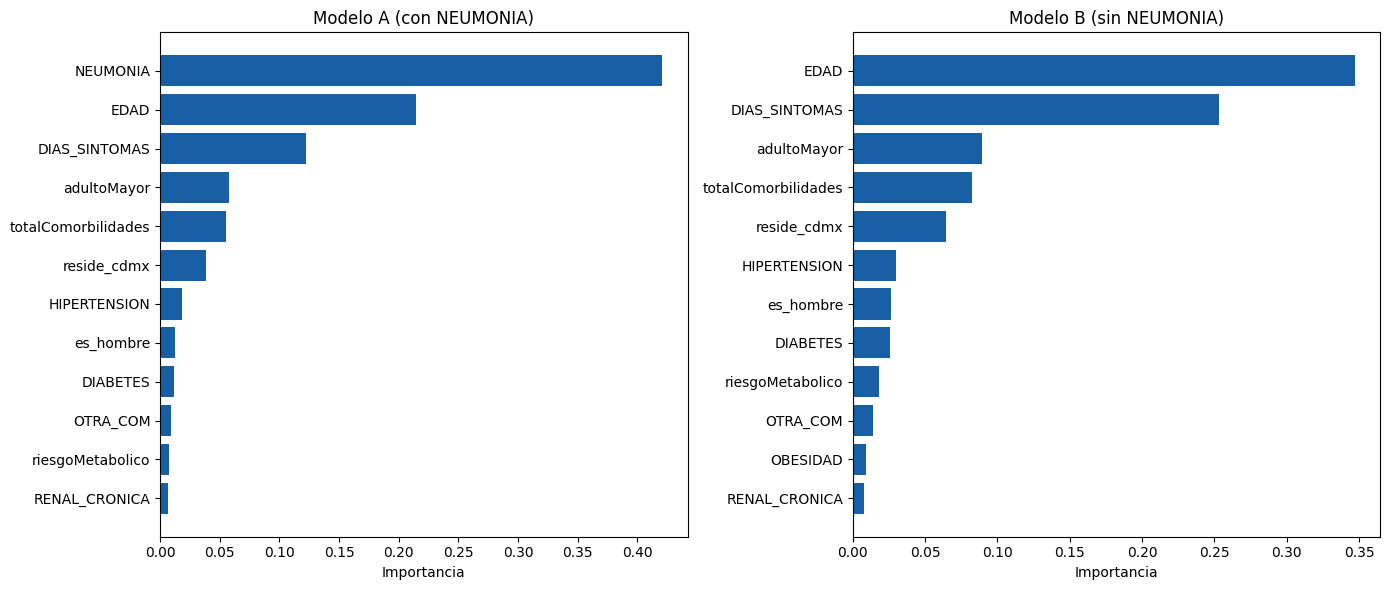

--- Modelo A (ranking completo) ---
NEUMONIA                  0.4210
EDAD                      0.2142
DIAS_SINTOMAS             0.1220
adultoMayor               0.0576
totalComorbilidades       0.0555
reside_cdmx               0.0388
HIPERTENSION              0.0182
es_hombre                 0.0124
DIABETES                  0.0117
OTRA_COM                  0.0087
riesgoMetabolico          0.0070
RENAL_CRONICA             0.0063
EMBARAZO                  0.0063
INMUSUPR                  0.0049
TABAQUISMO                0.0046
OBESIDAD                  0.0046
CARDIOVASCULAR            0.0022
ASMA                      0.0022
EPOC                      0.0018

--- Modelo B (ranking completo) ---
EDAD                      0.3472
DIAS_SINTOMAS             0.2533
adultoMayor               0.0893
totalComorbilidades       0.0824
reside_cdmx               0.0648
HIPERTENSION              0.0300
es_hombre                 0.0266
DIABETES                  0.0258
riesgoMetabolico          0.0181
OTR

In [17]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, modelo_id, preds in zip(axes, ["A", "B"], [predictoras_A, predictoras_B]):
    rf = modelos[modelo_id]["RandomForest"]
    importancias = rf.feature_importances_
    orden = np.argsort(importancias)[::-1][:12]
    ax.barh([preds[i] for i in orden][::-1], [importancias[i] for i in orden][::-1], color="#185FA5")
    ax.set_title(f"Modelo {modelo_id} ({'con' if modelo_id=='A' else 'sin'} NEUMONIA)")
    ax.set_xlabel("Importancia")
plt.tight_layout()
plt.savefig("factores_importantes.png", dpi=150)
plt.show()

print("--- Modelo A (ranking completo) ---")
for i in np.argsort(modelos["A"]["RandomForest"].feature_importances_)[::-1]:
    print(f"{predictoras_A[i]:25s} {modelos['A']['RandomForest'].feature_importances_[i]:.4f}")
print()
print("--- Modelo B (ranking completo) ---")
for i in np.argsort(modelos["B"]["RandomForest"].feature_importances_)[::-1]:
    print(f"{predictoras_B[i]:25s} {modelos['B']['RandomForest'].feature_importances_[i]:.4f}")

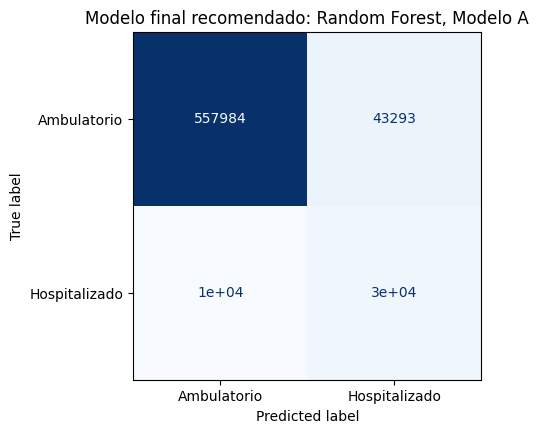

In [18]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(5, 5))
cm = confusion_matrix(y_test, predicciones["A"]["RandomForest"]["y_pred"])
ConfusionMatrixDisplay(cm, display_labels=["Ambulatorio", "Hospitalizado"]).plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("Modelo final recomendado: Random Forest, Modelo A")
plt.tight_layout()
plt.savefig("matriz_confusion_final.png", dpi=150)
plt.show()

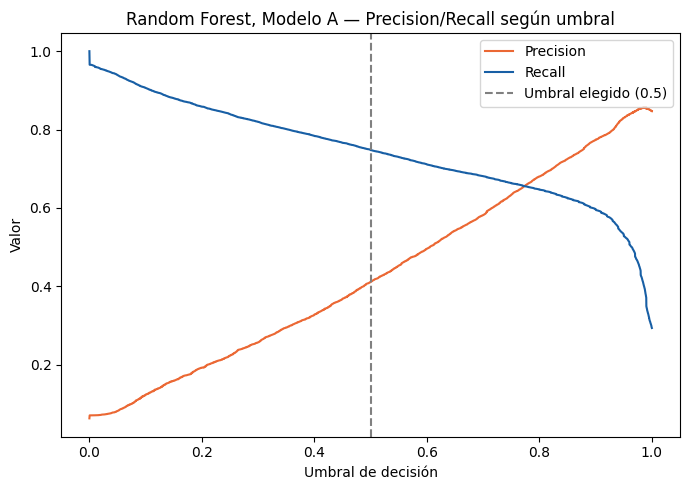

In [19]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(y_test, predicciones["A"]["RandomForest"]["y_proba"])
plt.figure(figsize=(7, 5))
plt.plot(thresholds, precision[:-1], label="Precision", color="#eb6834")
plt.plot(thresholds, recall[:-1], label="Recall", color="#185FA5")
plt.axvline(0.5, color="gray", linestyle="--", label="Umbral elegido (0.5)")
plt.xlabel("Umbral de decisión")
plt.ylabel("Valor")
plt.title("Random Forest, Modelo A — Precision/Recall según umbral")
plt.legend()
plt.tight_layout()
plt.savefig("precision_recall_umbral.png", dpi=150)
plt.show()

In [2]:
import polars as pl
from pathlib import Path

path = Path().cwd().parent / "data" / "polars" / "mexico_city_covid_data_dates.parquet"
lf_raw = pl.scan_parquet(path)

comorbilidades = [
    "DIABETES", "HIPERTENSION", "OBESIDAD", "EPOC", "ASMA",
    "CARDIOVASCULAR", "RENAL_CRONICA", "INMUSUPR", "TABAQUISMO", "OTRA_COM",
]
filtro_confirmados_cdmx = (
    pl.col("CLASIFICACION_FINAL_COVID").is_in(["1", "2", "3"])
    & (pl.col("ENTIDAD_UM") == "09")
)
mask_faltantes = (
    pl.any_horizontal([pl.col(c) == "98" for c in comorbilidades])
    | (pl.col("NEUMONIA") == "99")
    | (pl.col("EMBARAZO") == "98")
)

lf_base = lf_raw.filter(filtro_confirmados_cdmx).with_columns(
    mask_faltantes.alias("tiene_faltantes"),
    (pl.col("TIPO_PACIENTE") == "2").cast(pl.Int8).alias("hospitalizado"),
)

resumen = (
    lf_base.group_by("tiene_faltantes")
    .agg(pl.len().alias("n"), pl.col("hospitalizado").mean().round(4).alias("tasa_hospitalizacion"))
    .collect(engine="streaming")
)
print(resumen)

shape: (2, 3)
┌─────────────────┬─────────┬──────────────────────┐
│ tiene_faltantes ┆ n       ┆ tasa_hospitalizacion │
│ ---             ┆ ---     ┆ ---                  │
│ bool            ┆ u32     ┆ f64                  │
╞═════════════════╪═════════╪══════════════════════╡
│ false           ┆ 2140258 ┆ 0.0633               │
│ true            ┆ 25612   ┆ 0.0627               │
└─────────────────┴─────────┴──────────────────────┘


In [4]:
from scipy.stats import norm
import numpy as np

n1, p1 = 2_140_258, 0.0633   # conservados
n2, p2 = 25_612, 0.0627      # eliminados por faltantes

p_pool = (n1 * p1 + n2 * p2) / (n1 + n2)
se = np.sqrt(p_pool * (1 - p_pool) * (1 / n1 + 1 / n2))
z = (p1 - p2) / se
p_valor = 2 * (1 - norm.cdf(abs(z)))

print(f"z = {z:.3f}  |  p-valor = {p_valor:.3f}")

z = 0.392  |  p-valor = 0.695


III. Aprendizaje no supervisado

In [6]:
import polars as pl
import numpy as np
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# --- Reconstrucción rápida: parquet procesado + paso 7 (split) + paso 8 (escalamiento) ---
path = Path().cwd().parent / "data" / "polars" / "processed" / "hospitalizacion_features.parquet"
df = pl.read_parquet(path)

predictoras_A = [c for c in df.columns if c not in ["hospitalizado", "MUNICIPIO_RES"]]
X_A = df.select(predictoras_A).to_numpy()
y = df["hospitalizado"].to_numpy()

idx_train, idx_test = train_test_split(
    np.arange(len(y)), test_size=0.30, stratify=y, random_state=42
)
X_A_train, X_A_test = X_A[idx_train], X_A[idx_test]
y_train, y_test = y[idx_train], y[idx_test]

col_a = {name: i for i, name in enumerate(predictoras_A)}
cols_continuas = ["EDAD", "DIAS_SINTOMAS", "totalComorbilidades"]
idx_cont = [col_a[c] for c in cols_continuas]

scaler_A = MinMaxScaler()
X_A_train_s = X_A_train.astype(np.float64).copy()
X_A_test_s = X_A_test.astype(np.float64).copy()
X_A_train_s[:, idx_cont] = scaler_A.fit_transform(X_A_train[:, idx_cont])
X_A_test_s[:, idx_cont] = scaler_A.transform(X_A_test[:, idx_cont])

print(f"X_A_train_s: {X_A_train_s.shape} | X_A_test_s: {X_A_test_s.shape}")
print(f"Balance train: {y_train.mean():.4f} | Balance test: {y_test.mean():.4f}")
print()

# --- Método del codo + silhouette para K-Means ---
rng = np.random.RandomState(42)
idx_sil = rng.choice(len(X_A_train_s), size=30_000, replace=False)

inercias, siluetas = [], []
rango_k = range(2, 9)

for k in rango_k:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_A_train_s)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X_A_train_s[idx_sil], labels[idx_sil]))
    print(f"K={k}  inercia={km.inertia_:,.0f}  silhouette={siluetas[-1]:.4f}")

X_A_train_s: (1497713, 19) | X_A_test_s: (641878, 19)
Balance train: 0.0633 | Balance test: 0.0633

K=2  inercia=1,108,735  silhouette=0.3607
K=3  inercia=915,155  silhouette=0.3953
K=4  inercia=787,390  silhouette=0.4256
K=5  inercia=695,677  silhouette=0.4564
K=6  inercia=656,651  silhouette=0.4788
K=7  inercia=598,108  silhouette=0.4972
K=8  inercia=574,246  silhouette=0.4974


In [7]:
# --- Modelo final K-Means (K=7): Entrenamiento y Prueba ---
kmeans_final = KMeans(n_clusters=7, random_state=42, n_init=10)
clusters_train = kmeans_final.fit_predict(X_A_train_s)   # Entrenamiento
clusters_test = kmeans_final.predict(X_A_test_s)          # Prueba

# --- Perfil de cada cluster (centroides en escala 0-1) ---
df_centroides = pl.DataFrame(kmeans_final.cluster_centers_, schema=predictoras_A)
df_centroides = df_centroides.with_columns(pl.Series("cluster", range(7)))
with pl.Config(tbl_cols=-1, tbl_width_chars=250):
    print(df_centroides)

# --- Validación externa: tasa real de hospitalización por cluster (train y test) ---
resumen_train = (
    pl.DataFrame({"cluster": clusters_train, "hospitalizado": y_train})
    .group_by("cluster")
    .agg(pl.len().alias("n"), pl.col("hospitalizado").mean().round(4).alias("tasa_hosp"))
    .sort("cluster")
)
resumen_test = (
    pl.DataFrame({"cluster": clusters_test, "hospitalizado": y_test})
    .group_by("cluster")
    .agg(pl.len().alias("n"), pl.col("hospitalizado").mean().round(4).alias("tasa_hosp"))
    .sort("cluster")
)
print("--- Train ---")
print(resumen_train)
print("--- Test ---")
print(resumen_test)

shape: (7, 20)
┌──────────┬─────────────┬────────────┬─────────────┬─────────────┬─────────────┬────────────┬────────────┬────────────┬──────────┬──────────┬────────────┬────────────┬──────────┬────────────┬──────────┬────────────┬────────────┬──────────┬─────────┐
│ EDAD     ┆ adultoMayor ┆ es_hombre  ┆ EMBARAZO    ┆ DIAS_SINTOM ┆ reside_cdmx ┆ DIABETES   ┆ HIPERTENSI ┆ OBESIDAD   ┆ EPOC     ┆ ASMA     ┆ CARDIOVASC ┆ RENAL_CRON ┆ INMUSUPR ┆ TABAQUISMO ┆ OTRA_COM ┆ totalComor ┆ riesgoMeta ┆ NEUMONIA ┆ cluster │
│ ---      ┆ ---         ┆ ---        ┆ ---         ┆ AS          ┆ ---         ┆ ---        ┆ ON         ┆ ---        ┆ ---      ┆ ---      ┆ ULAR       ┆ ICA        ┆ ---      ┆ ---        ┆ ---      ┆ bilidades  ┆ bolico     ┆ ---      ┆ ---     │
│ f64      ┆ f64         ┆ f64        ┆ f64         ┆ ---         ┆ f64         ┆ f64        ┆ ---        ┆ f64        ┆ f64      ┆ f64      ┆ ---        ┆ ---        ┆ f64      ┆ f64        ┆ f64      ┆ ---        ┆ ---        ┆ f6

In [8]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, accuracy_score

clusters_alto_riesgo = [0, 3]
pred_test = np.isin(clusters_test, clusters_alto_riesgo).astype(int)

cm = confusion_matrix(y_test, pred_test)
print("Matriz de confusión (K-Means: clusters 0+3 = 'alto riesgo' vs hospitalizado real)")
print(f"              Pred: Bajo riesgo   Pred: Alto riesgo")
print(f"Real Ambulat. {cm[0,0]:15,d}  {cm[0,1]:15,d}")
print(f"Real Hospit.  {cm[1,0]:15,d}  {cm[1,1]:15,d}")
print()
print(f"Accuracy:  {accuracy_score(y_test, pred_test):.4f}")
print(f"Precision: {precision_score(y_test, pred_test):.4f}")
print(f"Recall:    {recall_score(y_test, pred_test):.4f}")
print(f"F1-Score:  {f1_score(y_test, pred_test):.4f}")

Matriz de confusión (K-Means: clusters 0+3 = 'alto riesgo' vs hospitalizado real)
              Pred: Bajo riesgo   Pred: Alto riesgo
Real Ambulat.         517,011           84,266
Real Hospit.           18,461           22,140

Accuracy:  0.8400
Precision: 0.2081
Recall:    0.5453
F1-Score:  0.3012


Algoritmo 2 de 4: PCA (Reducción de dimensionalidad)

PC 1: varianza=0.2521  acumulada=0.2521
PC 2: varianza=0.2066  acumulada=0.4588
PC 3: varianza=0.1071  acumulada=0.5659
PC 4: varianza=0.1024  acumulada=0.6683
PC 5: varianza=0.0722  acumulada=0.7405
PC 6: varianza=0.0631  acumulada=0.8036
PC 7: varianza=0.0517  acumulada=0.8553
PC 8: varianza=0.0441  acumulada=0.8994
PC 9: varianza=0.0192  acumulada=0.9186
PC10: varianza=0.0148  acumulada=0.9334
PC11: varianza=0.0121  acumulada=0.9455
PC12: varianza=0.0113  acumulada=0.9568
PC13: varianza=0.0100  acumulada=0.9668
PC14: varianza=0.0088  acumulada=0.9755
PC15: varianza=0.0070  acumulada=0.9825
PC16: varianza=0.0060  acumulada=0.9885
PC17: varianza=0.0058  acumulada=0.9943
PC18: varianza=0.0057  acumulada=1.0000
PC19: varianza=0.0000  acumulada=1.0000
shape: (19, 3)
┌──────────────────┬───────────┬───────────┐
│ variable         ┆ PC1       ┆ PC2       │
│ ---              ┆ ---       ┆ ---       │
│ str              ┆ f64       ┆ f64       │
╞══════════════════╪═══════════╪═══════════╡


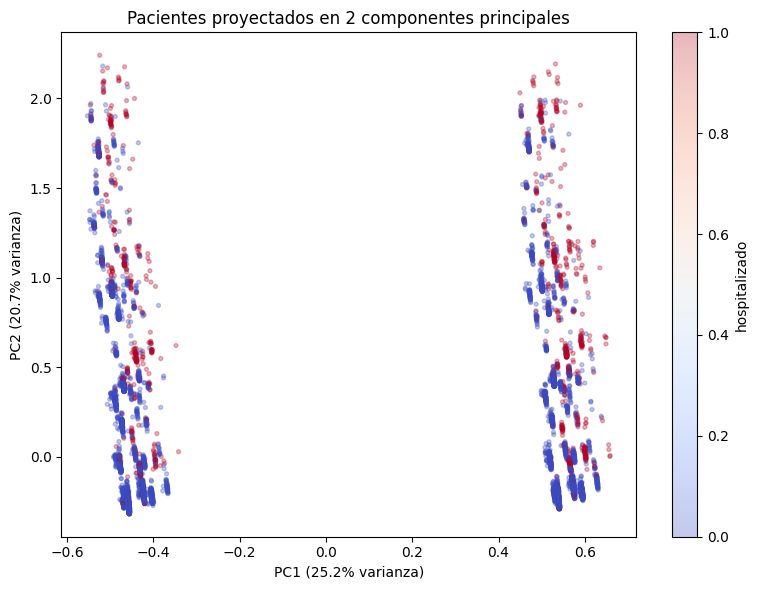

In [9]:
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt

# --- Entrenamiento: varianza explicada por componente ---
pca_full = PCA(random_state=42)
pca_full.fit(X_A_train_s)

varianza = pca_full.explained_variance_ratio_
acumulada = np.cumsum(varianza)
for i, (v, va) in enumerate(zip(varianza, acumulada), start=1):
    print(f"PC{i:2d}: varianza={v:.4f}  acumulada={va:.4f}")

# --- Cargas (loadings) de PC1 y PC2: qué variables originales las componen ---
cargas = pl.DataFrame(
    {"variable": predictoras_A, "PC1": pca_full.components_[0], "PC2": pca_full.components_[1]}
).sort("PC1", descending=True)
print(cargas)

# --- Visualización: PC1 vs PC2, coloreado por hospitalizado real (muestra de 20,000) ---
pca_2d = PCA(n_components=2, random_state=42).fit(X_A_train_s)
X_2d = pca_2d.transform(X_A_train_s)

idx_plot = np.random.RandomState(42).choice(len(X_2d), size=20_000, replace=False)
plt.figure(figsize=(8, 6))
plt.scatter(X_2d[idx_plot, 0], X_2d[idx_plot, 1], c=y_train[idx_plot], cmap="coolwarm", alpha=0.3, s=8)
plt.xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}% varianza)")
plt.ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}% varianza)")
plt.title("Pacientes proyectados en 2 componentes principales")
plt.colorbar(label="hospitalizado")
plt.tight_layout()
plt.savefig("pca_2d.png", dpi=150)
plt.show()

In [10]:
from sklearn.metrics import precision_recall_curve, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

# --- Prueba: proyectar el test con el PCA ya entrenado (no se reajusta) ---
X_2d_test = pca_2d.transform(X_A_test_s)
pc2_train = X_2d[:, 1]
pc2_test = X_2d_test[:, 1]

# --- Optimización: umbral de PC2 que maximiza F1, buscado SOLO en train ---
precisions, recalls, thresholds = precision_recall_curve(y_train, pc2_train)
f1s = 2 * precisions * recalls / (precisions + recalls + 1e-12)
umbral_pc2 = float(thresholds[np.argmax(f1s[:-1])])
print(f"Umbral óptimo de PC2 (alto riesgo si PC2 >= umbral): {umbral_pc2:.4f}")

# --- Evaluación final, una sola vez, en test ---
pred_test = (pc2_test >= umbral_pc2).astype(int)
cm = confusion_matrix(y_test, pred_test)
print(f"              Pred: Bajo riesgo   Pred: Alto riesgo")
print(f"Real Ambulat. {cm[0,0]:15,d}  {cm[0,1]:15,d}")
print(f"Real Hospit.  {cm[1,0]:15,d}  {cm[1,1]:15,d}")
print()
print(f"Accuracy:  {accuracy_score(y_test, pred_test):.4f}")
print(f"Precision: {precision_score(y_test, pred_test):.4f}")
print(f"Recall:    {recall_score(y_test, pred_test):.4f}")
print(f"F1-Score:  {f1_score(y_test, pred_test):.4f}")

Umbral óptimo de PC2 (alto riesgo si PC2 >= umbral): 0.4622
              Pred: Bajo riesgo   Pred: Alto riesgo
Real Ambulat.         552,413           48,864
Real Hospit.           19,195           21,406

Accuracy:  0.8940
Precision: 0.3046
Recall:    0.5272
F1-Score:  0.3861


Algoritmo 3 de 4: Isolation Forest (Detección de anomalías)

In [11]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, accuracy_score

# --- Entrenamiento y Prueba ---
iso_forest = IsolationForest(contamination=0.01, random_state=42, n_jobs=-1)
anomalias_train = iso_forest.fit_predict(X_A_train_s)   # -1 = anomalía, 1 = normal
anomalias_test = iso_forest.predict(X_A_test_s)

print(f"Anomalías en train: {(anomalias_train == -1).sum():,} ({(anomalias_train == -1).mean()*100:.2f}%)")
print(f"Anomalías en test:  {(anomalias_test == -1).sum():,} ({(anomalias_test == -1).mean()*100:.2f}%)")
print()

# --- Validación externa: ¿coincide con el hallazgo del paso 5? ---
mask_ocho = (df["totalComorbilidades"] == 8).to_numpy()
mask_ocho_test = mask_ocho[idx_test]

tasa_grupo = (anomalias_test[mask_ocho_test] == -1).mean() * 100
tasa_general = (anomalias_test == -1).mean() * 100
print(f"Pacientes con 8 comorbilidades en test: {mask_ocho_test.sum()}")
print(f"Tasa de anomalía en ESE grupo: {tasa_grupo:.1f}%")
print(f"Tasa de anomalía general:      {tasa_general:.1f}%")
print()

# --- Evaluación: matriz de confusión (grupo conocido vs marcado por el algoritmo) ---
y_true_anom = mask_ocho_test.astype(int)
y_pred_anom = (anomalias_test == -1).astype(int)
cm = confusion_matrix(y_true_anom, y_pred_anom)
print(f"              Pred: Normal   Pred: Anomalía")
print(f"Real Normal   {cm[0,0]:11,d}  {cm[0,1]:11,d}")
print(f"Real 8-comorb.{cm[1,0]:11,d}  {cm[1,1]:11,d}")
print()
print(f"Accuracy:  {accuracy_score(y_true_anom, y_pred_anom):.4f}")
print(f"Precision: {precision_score(y_true_anom, y_pred_anom):.4f}")
print(f"Recall:    {recall_score(y_true_anom, y_pred_anom):.4f}")
print(f"F1-Score:  {f1_score(y_true_anom, y_pred_anom):.4f}")

Anomalías en train: 14,977 (1.00%)
Anomalías en test:  6,295 (0.98%)

Pacientes con 8 comorbilidades en test: 50
Tasa de anomalía en ESE grupo: 100.0%
Tasa de anomalía general:      1.0%

              Pred: Normal   Pred: Anomalía
Real Normal       635,583        6,245
Real 8-comorb.          0           50

Accuracy:  0.9903
Precision: 0.0079
Recall:    1.0000
F1-Score:  0.0158


In [12]:
# --- Optimización: umbral más estricto que aún capture el 100% del grupo conocido ---
mask_ocho_train = mask_ocho[idx_train]
scores_train = iso_forest.score_samples(X_A_train_s)   # más negativo = más anómalo
scores_ocho_train = scores_train[mask_ocho_train]
umbral_optimo = scores_ocho_train.max()   # el "menos anómalo" de los 168 conocidos, en train

n_flagged_train = (scores_train <= umbral_optimo).sum()
print(f"Umbral óptimo (buscado en train): {umbral_optimo:.4f}")
print(f"Total marcado en train con este umbral: {n_flagged_train:,} (vs. {int(len(scores_train)*0.01):,} con contamination=0.01)")
print()

# --- Evaluación final, una sola vez, en test ---
scores_test = iso_forest.score_samples(X_A_test_s)
pred_test_optimo = (scores_test <= umbral_optimo).astype(int)

cm2 = confusion_matrix(y_true_anom, pred_test_optimo)
print(f"              Pred: Normal   Pred: Anomalía")
print(f"Real Normal   {cm2[0,0]:11,d}  {cm2[0,1]:11,d}")
print(f"Real 8-comorb.{cm2[1,0]:11,d}  {cm2[1,1]:11,d}")
print()
print(f"Accuracy:  {accuracy_score(y_true_anom, pred_test_optimo):.4f}")
print(f"Precision: {precision_score(y_true_anom, pred_test_optimo):.4f}")
print(f"Recall:    {recall_score(y_true_anom, pred_test_optimo):.4f}")
print(f"F1-Score:  {f1_score(y_true_anom, pred_test_optimo):.4f}")

Umbral óptimo (buscado en train): -0.7700
Total marcado en train con este umbral: 192 (vs. 14,977 con contamination=0.01)

              Pred: Normal   Pred: Anomalía
Real Normal       641,800           28
Real 8-comorb.          0           50

Accuracy:  1.0000
Precision: 0.6410
Recall:    1.0000
F1-Score:  0.7812


In [13]:
# --- ¿Qué son los 28 casos adicionales marcados? ---
mask_extra = (pred_test_optimo == 1) & (y_true_anom == 0)
idx_extra = np.where(mask_extra)[0]

df_extra = pl.DataFrame({
    "EDAD": X_A_test[idx_extra, col_a["EDAD"]],
    "totalComorbilidades": X_A_test[idx_extra, col_a["totalComorbilidades"]],
    "hospitalizado": y_test[idx_extra],
})
print(df_extra.describe())

shape: (9, 4)
┌────────────┬───────────┬─────────────────────┬───────────────┐
│ statistic  ┆ EDAD      ┆ totalComorbilidades ┆ hospitalizado │
│ ---        ┆ ---       ┆ ---                 ┆ ---           │
│ str        ┆ f64       ┆ f64                 ┆ f64           │
╞════════════╪═══════════╪═════════════════════╪═══════════════╡
│ count      ┆ 28.0      ┆ 28.0                ┆ 28.0          │
│ null_count ┆ 0.0       ┆ 0.0                 ┆ 0.0           │
│ mean       ┆ 62.928571 ┆ 5.607143            ┆ 0.642857      │
│ std        ┆ 20.544313 ┆ 1.13331             ┆ 0.48795       │
│ min        ┆ 18.0      ┆ 3.0                 ┆ 0.0           │
│ 25%        ┆ 53.0      ┆ 5.0                 ┆ 0.0           │
│ 50%        ┆ 68.0      ┆ 6.0                 ┆ 1.0           │
│ 75%        ┆ 77.0      ┆ 6.0                 ┆ 1.0           │
│ max        ┆ 90.0      ┆ 7.0                 ┆ 1.0           │
└────────────┴───────────┴─────────────────────┴───────────────┘


Algoritmo 4 de 4: Reglas de Asociación

In [16]:
import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules

items_binarios_x = [
    "es_hombre", "EMBARAZO", "reside_cdmx", "NEUMONIA",
    "DIABETES", "HIPERTENSION", "OBESIDAD", "EPOC", "ASMA",
    "CARDIOVASCULAR", "RENAL_CRONICA", "INMUSUPR", "TABAQUISMO", "OTRA_COM",
    "adultoMayor", "riesgoMetabolico",
]
idx_items = [col_a[c] for c in items_binarios_x]

# --- Entrenamiento: extraer itemsets y reglas frecuentes SOLO de train ---
df_transacciones_train = pd.DataFrame(
    X_A_train[:, idx_items].astype(bool), columns=items_binarios_x
)
df_transacciones_train["hospitalizado"] = y_train.astype(bool)   # se agrega aparte, desde y_train

itemsets = apriori(df_transacciones_train, min_support=0.02, use_colnames=True)
reglas = association_rules(itemsets, metric="confidence", min_threshold=0.3)

print(f"Itemsets frecuentes encontrados: {len(itemsets)}")
print(f"Reglas totales (confianza >= 0.3): {len(reglas)}")
print()

reglas_hosp = reglas[
    reglas["consequents"].apply(lambda x: x == frozenset({"hospitalizado"}))
].sort_values("lift", ascending=False)

print(f"Reglas que apuntan a 'hospitalizado': {len(reglas_hosp)}")
with pd.option_context("display.max_colwidth", None, "display.width", 200):
    print(reglas_hosp[["antecedents", "support", "confidence", "lift"]].head(15))

Itemsets frecuentes encontrados: 67
Reglas totales (confianza >= 0.3): 164

Reglas que apuntan a 'hospitalizado': 4
                            antecedents   support  confidence       lift
106  frozenset({adultoMayor, NEUMONIA})  0.020404    0.911610  14.412255
58     frozenset({es_hombre, NEUMONIA})  0.024300    0.824905  13.041479
20                frozenset({NEUMONIA})  0.040033    0.790565  12.498563
70   frozenset({reside_cdmx, NEUMONIA})  0.028666    0.764300  12.083322


In [18]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

# --- c-ii) Prueba: ¿las 4 reglas se sostienen en test, o eran ruido de train? ---
df_transacciones_test = pd.DataFrame(
    X_A_test[:, idx_items].astype(bool), columns=items_binarios_x
)
df_transacciones_test["hospitalizado"] = y_test.astype(bool)

print(f"{'Regla':45s} {'Conf. train':12s} {'Conf. test':12s}")
for _, row in reglas_hosp.iterrows():
    cols = list(row["antecedents"])
    antecedente_test = df_transacciones_test[cols].all(axis=1)
    conf_test = (antecedente_test & df_transacciones_test["hospitalizado"]).sum() / antecedente_test.sum()
    print(f"{str(cols):45s} {row['confidence']:.4f}       {conf_test:.4f}")
print()

# --- d) Evaluación + e) Optimización: regla angosta (precisión) vs. regla amplia (recall) ---
pred_angosta = (
    (X_A_test[:, col_a["adultoMayor"]] == 1) & (X_A_test[:, col_a["NEUMONIA"]] == 1)
).astype(int)
pred_amplia = (X_A_test[:, col_a["NEUMONIA"]] == 1).astype(int)

for nombre, pred in [("Regla angosta (adultoMayor + NEUMONIA)", pred_angosta), ("Regla amplia (solo NEUMONIA)", pred_amplia)]:
    cm = confusion_matrix(y_test, pred)
    print(f"--- {nombre} ---")
    print(f"              Pred: No hosp.   Pred: Hosp.")
    print(f"Real No hosp. {cm[0,0]:13,d}  {cm[0,1]:13,d}")
    print(f"Real Hosp.    {cm[1,0]:13,d}  {cm[1,1]:13,d}")
    print(f"Accuracy:  {accuracy_score(y_test, pred):.4f}")
    print(f"Precision: {precision_score(y_test, pred):.4f}")
    print(f"Recall:    {recall_score(y_test, pred):.4f}")
    print(f"F1-Score:  {f1_score(y_test, pred):.4f}")
    print()

Regla                                         Conf. train  Conf. test  
['adultoMayor', 'NEUMONIA']                   0.9116       0.9121
['es_hombre', 'NEUMONIA']                     0.8249       0.8237
['NEUMONIA']                                  0.7906       0.7913
['reside_cdmx', 'NEUMONIA']                   0.7643       0.7636

--- Regla angosta (adultoMayor + NEUMONIA) ---
              Pred: No hosp.   Pred: Hosp.
Real No hosp.       600,012          1,265
Real Hosp.           27,476         13,125
Accuracy:  0.9552
Precision: 0.9121
Recall:    0.3233
F1-Score:  0.4774

--- Regla amplia (solo NEUMONIA) ---
              Pred: No hosp.   Pred: Hosp.
Real No hosp.       594,500          6,777
Real Hosp.           14,902         25,699
Accuracy:  0.9662
Precision: 0.7913
Recall:    0.6330
F1-Score:  0.7033



In [1]:
import polars as pl 
from pathlib import Path
path = Path().cwd().parent / "data" / "mexico_city_covid_final_report.csv"
df = pl.read_csv(path)
muestra = df.sample(fraction=0.03, seed=42)
output_path = Path().cwd().parent / "data" / "mexico_city_covid_final_report_3_sample.csv"
muestra.write_csv(output_path)  


In [2]:
import polars as pl 
from pathlib import Path
path = Path().cwd().parent / "data" / "data-studio" / "mexico_city_covid_final_report_3_sample_clean.csv"
df = pl.read_csv(path)
muestra = df.sample(fraction=0.5, seed=42)
output_path = Path().cwd().parent / "data" / "data-studio" / "mexico_city_covid_final_report_3_sample_clean_excel.csv"
muestra.write_csv(output_path)  


In [8]:
print(df["FECHA_DEF"].dtype)
print(df["FECHA_DEF"].null_count())
print(df["FECHA_DEF"].value_counts().sort("count", descending=True).head(8))
print("defunciones reales:", df.filter(pl.col("FECHA_DEF").is_not_null()).height)

String
232293
shape: (8, 2)
┌────────────┬────────┐
│ FECHA_DEF  ┆ count  │
│ ---        ┆ ---    │
│ str        ┆ u32    │
╞════════════╪════════╡
│ null       ┆ 232293 │
│ 2021-01-10 ┆ 18     │
│ 2021-01-26 ┆ 16     │
│ 2021-01-17 ┆ 16     │
│ 2021-01-03 ┆ 16     │
│ 2021-02-03 ┆ 16     │
│ 2021-01-12 ┆ 15     │
│ 2021-01-19 ┆ 15     │
└────────────┴────────┘
defunciones reales: 2913


In [ ]:
import polars as pl 
from pathlib import Path
path = Path().cwd().parent / "data" / "data-studio" / "mexico_city_covid_final_report_3_sample_clean.csv"
df = pl.read_csv(path)
print(f"filas: {df.shape[0]:,} | columnas: {df.shape[1]:,}")
print(df.columns)

In [15]:
print(df["FECHA_DEF"].dtype)
print(df.filter(pl.col("FECHA_SINTOMAS").is_not_null()).get_column("FECHA_SINTOMAS").value_counts().sort("count", descending=True).head(8))

String
shape: (8, 2)
┌────────────────┬───────┐
│ FECHA_SINTOMAS ┆ count │
│ ---            ┆ ---   │
│ str            ┆ u32   │
╞════════════════╪═══════╡
│ 2022-01-10     ┆ 1580  │
│ 2022-01-17     ┆ 1201  │
│ 2022-01-11     ┆ 1061  │
│ 2022-01-14     ┆ 1003  │
│ 2022-01-12     ┆ 965   │
│ 2022-01-18     ┆ 959   │
│ 2022-01-07     ┆ 949   │
│ 2022-01-13     ┆ 922   │
└────────────────┴───────┘


In [16]:
conf = df.filter(pl.col("CLASIFICACION_FINAL_COVID").str.contains("CONFIRMADO"))
print("confirmados:", conf.height)
print("defunciones confirmadas:", conf.filter(pl.col("FECHA_DEF").is_not_null()).height)
print("letalidad:", conf.filter(pl.col("FECHA_DEF").is_not_null()).height / conf.height)
print("rango fechas:", df["FECHA_SINTOMAS"].min(), "→", df["FECHA_SINTOMAS"].max())

confirmados: 72358
defunciones confirmadas: 2179
letalidad: 0.030114154620083475
rango fechas: 2020-01-01 → 2026-05-10


In [17]:
print(f"Numero de filas: {df.shape[0]:,} | Numero de columnas: {df.shape[1]:,}")

Numero de filas: 235,206 | Numero de columnas: 44


In [19]:
print(df["UCI"].value_counts())
print(df["DIABETES"].value_counts())

shape: (4, 2)
┌─────────────────┬────────┐
│ UCI             ┆ count  │
│ ---             ┆ ---    │
│ str             ┆ u32    │
╞═════════════════╪════════╡
│ NO ESPECIFICADO ┆ 51     │
│ NO              ┆ 9808   │
│ SI              ┆ 623    │
│ NO APLICA       ┆ 224724 │
└─────────────────┴────────┘
shape: (3, 2)
┌───────────┬────────┐
│ DIABETES  ┆ count  │
│ ---       ┆ ---    │
│ str       ┆ u32    │
╞═══════════╪════════╡
│ NO        ┆ 217593 │
│ SI        ┆ 15315  │
│ SE IGNORA ┆ 2298   │
└───────────┴────────┘


In [20]:
print(df["TIPO_PACIENTE"].value_counts())
print(df["INTUBADO"].value_counts())

shape: (2, 2)
┌───────────────┬────────┐
│ TIPO_PACIENTE ┆ count  │
│ ---           ┆ ---    │
│ str           ┆ u32    │
╞═══════════════╪════════╡
│ HOSPITALIZADO ┆ 10482  │
│ AMBULATORIO   ┆ 224724 │
└───────────────┴────────┘
shape: (4, 2)
┌─────────────────┬────────┐
│ INTUBADO        ┆ count  │
│ ---             ┆ ---    │
│ str             ┆ u32    │
╞═════════════════╪════════╡
│ SI              ┆ 1099   │
│ NO APLICA       ┆ 224724 │
│ NO              ┆ 9332   │
│ NO ESPECIFICADO ┆ 51     │
└─────────────────┴────────┘


In [21]:
for c in ["SEXO","EMBARAZO","INDIGENA","HABLA_LENGUA_INDIG","MIGRANTE","NACIONALIDAD"]:
    print(df[c].value_counts().sort("count", descending=True))

shape: (2, 2)
┌────────┬────────┐
│ SEXO   ┆ count  │
│ ---    ┆ ---    │
│ str    ┆ u32    │
╞════════╪════════╡
│ MUJER  ┆ 126112 │
│ HOMBRE ┆ 109094 │
└────────┴────────┘
shape: (4, 2)
┌───────────┬────────┐
│ EMBARAZO  ┆ count  │
│ ---       ┆ ---    │
│ str       ┆ u32    │
╞═══════════╪════════╡
│ NO        ┆ 123053 │
│ NO APLICA ┆ 109094 │
│ SI        ┆ 1690   │
│ SE IGNORA ┆ 1369   │
└───────────┴────────┘
shape: (3, 2)
┌─────────────────┬────────┐
│ INDIGENA        ┆ count  │
│ ---             ┆ ---    │
│ str             ┆ u32    │
╞═════════════════╪════════╡
│ NO              ┆ 214127 │
│ NO ESPECIFICADO ┆ 20330  │
│ SI              ┆ 749    │
└─────────────────┴────────┘
shape: (3, 2)
┌────────────────────┬────────┐
│ HABLA_LENGUA_INDIG ┆ count  │
│ ---                ┆ ---    │
│ str                ┆ u32    │
╞════════════════════╪════════╡
│ NO                 ┆ 214200 │
│ NO ESPECIFICADO    ┆ 20496  │
│ SI                 ┆ 510    │
└────────────────────┴────────┘
shape

In [22]:
for c in ["ENTIDAD_UM","ENTIDAD_RES","MUNICIPIO","SECTOR","ORIGEN"]:
    print(c, df[c].n_unique())
    print(df[c].value_counts().sort("count", descending=True).head(8))

ENTIDAD_UM 32
shape: (8, 2)
┌─────────────────────┬────────┐
│ ENTIDAD_UM          ┆ count  │
│ ---                 ┆ ---    │
│ str                 ┆ u32    │
╞═════════════════════╪════════╡
│ CIUDAD DE MÉXICO    ┆ 219652 │
│ MÉXICO              ┆ 8246   │
│ QUERÉTARO           ┆ 1401   │
│ HIDALGO             ┆ 893    │
│ MORELOS             ┆ 539    │
│ BAJA CALIFORNIA SUR ┆ 446    │
│ GUANAJUATO          ┆ 440    │
│ QUINTANA ROO        ┆ 430    │
└─────────────────────┴────────┘
ENTIDAD_RES 32
shape: (8, 2)
┌─────────────────────┬────────┐
│ ENTIDAD_RES         ┆ count  │
│ ---                 ┆ ---    │
│ str                 ┆ u32    │
╞═════════════════════╪════════╡
│ CIUDAD DE MÉXICO    ┆ 192946 │
│ MÉXICO              ┆ 32779  │
│ QUERÉTARO           ┆ 1517   │
│ HIDALGO             ┆ 1227   │
│ MORELOS             ┆ 695    │
│ PUEBLA              ┆ 585    │
│ GUANAJUATO          ┆ 520    │
│ BAJA CALIFORNIA SUR ┆ 466    │
└─────────────────────┴────────┘
MUNICIPIO 928
shape

In [24]:
print(df["NEUMONIA"].value_counts())
print(df.select(["DIAS_SINTOMAS","DIAS_ATENCION","DIAS_ENFERMO"]).describe())
print(df.select([pl.col(c).null_count().alias(c) for c in ["DIAS_SINTOMAS","DIAS_ATENCION","DIAS_ENFERMO"]]))

shape: (3, 2)
┌─────────────────┬────────┐
│ NEUMONIA        ┆ count  │
│ ---             ┆ ---    │
│ str             ┆ u32    │
╞═════════════════╪════════╡
│ SI              ┆ 6501   │
│ NO ESPECIFICADO ┆ 1347   │
│ NO              ┆ 227358 │
└─────────────────┴────────┘
shape: (9, 4)
┌────────────┬───────────────┬───────────────┬──────────────┐
│ statistic  ┆ DIAS_SINTOMAS ┆ DIAS_ATENCION ┆ DIAS_ENFERMO │
│ ---        ┆ ---           ┆ ---           ┆ ---          │
│ str        ┆ f64           ┆ f64           ┆ f64          │
╞════════════╪═══════════════╪═══════════════╪══════════════╡
│ count      ┆ 235206.0      ┆ 2913.0        ┆ 2913.0       │
│ null_count ┆ 0.0           ┆ 232293.0      ┆ 232293.0     │
│ mean       ┆ 2.446094      ┆ 9.63989       ┆ 15.066941    │
│ std        ┆ 9.583822      ┆ 14.61579      ┆ 15.169531    │
│ min        ┆ 0.0           ┆ -1.0          ┆ 0.0          │
│ 25%        ┆ 0.0           ┆ 3.0           ┆ 7.0          │
│ 50%        ┆ 1.0           

In [26]:
comorb = ["DIABETES","HIPERTENSION","OBESIDAD","TABAQUISMO","CARDIOVASCULAR",
          "EPOC","ASMA","RENAL_CRONICA","INMUSUPR","OTRA_COM"]
for c in comorb:
    v = df[c].value_counts()
    si = v.filter(pl.col(c)=="SI")["count"].item() if v.filter(pl.col(c)=="SI").height else 0
    print(f"{c:16} SI={si:6,}  ({si/len(df)*100:.2f}%)")

    


DIABETES         SI=15,315  (6.51%)
HIPERTENSION     SI=20,168  (8.57%)
OBESIDAD         SI=16,198  (6.89%)
TABAQUISMO       SI=18,076  (7.69%)
CARDIOVASCULAR   SI= 2,190  (0.93%)
EPOC             SI= 1,192  (0.51%)
ASMA             SI= 4,396  (1.87%)
RENAL_CRONICA    SI= 1,436  (0.61%)
INMUSUPR         SI= 1,424  (0.61%)
OTRA_COM         SI= 2,327  (0.99%)


In [27]:
flags = [pl.col(c).eq("SI").cast(pl.Int8) for c in comorb]
df2 = df.with_columns(sum(flags).alias("n_comorb"))
print(df2["n_comorb"].value_counts().sort("n_comorb"))
print(df2.group_by("n_comorb").agg(
    (pl.col("FECHA_DEF").is_not_null().sum() / pl.len()).alias("letalidad")
).sort("n_comorb"))

shape: (11, 2)
┌──────────┬────────┐
│ n_comorb ┆ count  │
│ ---      ┆ ---    │
│ i8       ┆ u32    │
╞══════════╪════════╡
│ 0        ┆ 175977 │
│ 1        ┆ 41589  │
│ 2        ┆ 13123  │
│ 3        ┆ 3513   │
│ 4        ┆ 783    │
│ …        ┆ …      │
│ 6        ┆ 34     │
│ 7        ┆ 12     │
│ 8        ┆ 3      │
│ 9        ┆ 1      │
│ 10       ┆ 8      │
└──────────┴────────┘
shape: (11, 2)
┌──────────┬───────────┐
│ n_comorb ┆ letalidad │
│ ---      ┆ ---       │
│ i8       ┆ f64       │
╞══════════╪═══════════╡
│ 0        ┆ 0.005654  │
│ 1        ┆ 0.019693  │
│ 2        ┆ 0.047321  │
│ 3        ┆ 0.09963   │
│ 4        ┆ 0.123883  │
│ …        ┆ …         │
│ 6        ┆ 0.147059  │
│ 7        ┆ 0.25      │
│ 8        ┆ 0.333333  │
│ 9        ┆ 0.0       │
│ 10       ┆ 0.0       │
└──────────┴───────────┘
